# Prediksi Keterlambatan Paket — Kasus 08

**Mata kuliah:** Machine Learning · Kelas MKB 5B
**Anggota:** Bob Nolen Barnabas Munthe (2406157) · Muhammad Riyu Saputra (2403287)

**Tujuan.** Saat paket dijemput di hub Bandung, model memperkirakan peluang paket terlambat (melewati janji `janji_hari`), lalu memberi rekomendasi: *aman*, *kabari pelanggan*, atau *prioritaskan*.

**Metrik utama:** PR-AUC, dihitung sebagai *average precision* (AP) dari kurva precision–recall.

**Aturan yang dipegang di notebook ini**
1. Data **test (April–Juni 2026) dipisahkan sejak awal** dan tidak dipakai untuk EDA, pemilihan fitur, model, maupun threshold.
2. Semua nilai patokan (median, modus, threshold) dipelajari dari **train**; pemilihan model dan threshold memakai **validation**.
3. Fitur hanya memakai informasi yang **sudah tersedia saat paket dijemput**.

Data bersifat sintetis (dari pengajar), sehingga model ini adalah bahan pembelajaran, bukan sistem operasional.

## 1. Setup dan membaca data

In [1]:
import hashlib, itertools, json
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, confusion_matrix, PrecisionRecallDisplay
from IPython.display import display

pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110})
print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

pandas 3.0.5 | scikit-learn 1.9.1


CSV dibaca dari repositori pengajar. Sidik SHA-256 memastikan isinya sama dengan data yang dianalisis.
Jika URL tidak bisa diakses, unggah `raw.csv` ke panel *Files* Colab lalu ganti `SUMBER_DATA = '/content/raw.csv'`.

In [2]:
SUMBER_DATA = 'https://raw.githubusercontent.com/nurhikam/mkb-ml-project/main/kasus/08-keterlambatan-paket/data/raw.csv'

isi = urlopen(SUMBER_DATA, timeout=60).read() if SUMBER_DATA.startswith('https://') else Path(SUMBER_DATA).read_bytes()
assert hashlib.sha256(isi).hexdigest() == '2821b50eac1b02181cacbfb52fca784b2b5be930c73e5c671a877eeec6a600ab', 'Dataset berbeda!'
df = pd.read_csv(BytesIO(isi))
print('Ukuran data mentah:', df.shape)
display(df.head())

Ukuran data mentah: (40500, 13)


,id_resi,tanggal_pickup,jam_pickup,kota_tujuan,jarak_km,jumlah_transit,layanan,janji_hari,berat_kg,metode_bayar,cuaca_saat_pickup,volume_hub_hari,terlambat
0,BDG69958899,2025-01-01,14,Tasikmalaya,109.0,2,HEMAT,4,5.93,COD,berawan,4990,0
1,BDG98718051,2025-01-01,15,Surabaya,678.0,2,HEMAT,5,0.78,non_COD,berawan,4769,0
2,BDG40074637,2025-01-01,14,Bekasi,128.0,1,REG,2,2.57,COD,cerah,4286,0
3,BDG00168612,2025-01-01,14,Pontianak,885.0,3,REG,3,1.12,COD,cerah,4856,1
4,BDG72495951,2025-01-01,12,Denpasar,1057.0,3,EXPRESS,3,1.68,non_COD,berawan,5467,0


## 2. Memisahkan data test sejak awal
Duplikat persis dibuang dulu (satu baris = satu paket), lalu baris **April–Juni 2026** disimpan terpisah sebagai `test_mentah`.
Semua langkah sesudahnya hanya memakai `kerja` (train + validation) sampai bagian 9.

In [3]:
print('Duplikat persis:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
assert df['id_resi'].is_unique, 'Ada resi ganda dengan isi berbeda'

df['tanggal_pickup'] = pd.to_datetime(df['tanggal_pickup'])
test_mentah = df[df['tanggal_pickup'] >= '2026-04-01'].copy()     # disimpan, TIDAK dianalisis
kerja       = df[df['tanggal_pickup'] <  '2026-04-01'].copy()     # train + validation

print('Train + validation:', len(kerja), 'paket | Test (disimpan):', len(test_mentah), 'paket')

Duplikat persis: 500
Train + validation: 33256 paket | Test (disimpan): 6744 paket


## 3. Data cleaning
### 3.1 Masalah yang ditemukan

In [4]:
print('Varian kota   :', kerja['kota_tujuan'].nunique(), '→', sorted(kerja['kota_tujuan'].unique()))
print('Varian layanan:', kerja['layanan'].nunique(), '→', sorted(kerja['layanan'].unique()))
b = kerja['berat_kg']
print('\nBerat = -1                 :', (b == -1).sum())
print('Berat > 50                  :', (b > 50).sum())
print('Paket normal terberat (≤50) :', b[b <= 50].max(), '| nilai "raksasa" terkecil:', b[b > 50].min())
print('Median berat normal         :', b[(b > 0) & (b <= 50)].median(), '| median raksasa / 1000:', (b[b > 50] / 1000).median())
print('\nNilai kosong:'); print(kerja.isna().sum()[lambda s: s > 0])

Varian kota   : 28 → ['Bali', 'Balikpapan', 'Bekasi', 'Bogor', 'Cirebon', 'DI Yogyakarta', 'DKI Jakarta', 'Denpasar', 'Jakarta', 'Jkt', 'Jogja', 'Kota Bekasi', 'MEDAN', 'Makassar', 'Malang', 'Medan', 'Palembang', 'Pontianak', 'Sby', 'Semarang', 'Surabaya', 'Tasikmalaya', 'Yogya', 'Yogyakarta', 'bekasi', 'denpasar', 'jakarta', 'surabaya']
Varian layanan: 7 → ['EXP', 'EXPRESS', 'Express', 'HEMAT', 'REG', 'hemat', 'reg']

Berat = -1                 : 66
Berat > 50                  : 1019
Paket normal terberat (≤50) : 44.06 | nilai "raksasa" terkecil: 100.0
Median berat normal         : 1.34 | median raksasa / 1000: 1.33

Nilai kosong:
jarak_km             644
cuaca_saat_pickup    315
dtype: int64


| Masalah | Penanganan | Alasan |
|---|---|---|
| Ejaan kota (28 varian) dan layanan (7 varian) | disatukan dengan kamus | `Jkt`, `DKI Jakarta`, `jakarta` adalah kota yang sama |
| Berat = −1 | dijadikan kosong | kode "tidak tercatat" |
| Berat > 50 | dibagi 1.000 | ada celah kosong 44–100 dan median setelah dibagi (±1,33 kg) sama dengan median paket normal, jadi diduga kuat tercatat dalam gram |
| Jarak kosong | median jarak **kota yang sama** di train | jarak ke satu kota hampir tetap |
| Berat kosong | median berat train | berat tidak berpola terhadap kolom lain |
| Cuaca kosong | kategori `tidak_diketahui` | cuaca dalam satu hari bervariasi, tidak bisa ditebak |

### 3.2 Fungsi cleaning (dipakai sama persis untuk train, validation, test, dan aplikasi)

In [5]:
PETA_KOTA = {'jakarta': 'Jakarta', 'jkt': 'Jakarta', 'dki jakarta': 'Jakarta',
             'bekasi': 'Bekasi', 'kota bekasi': 'Bekasi', 'surabaya': 'Surabaya', 'sby': 'Surabaya',
             'medan': 'Medan', 'yogyakarta': 'Yogyakarta', 'di yogyakarta': 'Yogyakarta',
             'jogja': 'Yogyakarta', 'yogya': 'Yogyakarta', 'denpasar': 'Denpasar', 'bali': 'Denpasar'}

def rapikan(data):
    """Perbaikan yang tidak butuh statistik apa pun: ejaan, kode error, salah satuan."""
    d = data.copy()
    kota = d['kota_tujuan'].str.strip().str.lower()
    d['kota_tujuan'] = kota.map(PETA_KOTA).fillna(kota.str.title())
    d['layanan'] = d['layanan'].str.strip().str.upper().replace({'EXP': 'EXPRESS'})
    d.loc[d['berat_kg'] == -1, 'berat_kg'] = np.nan                       # kode tidak tercatat
    gram = d['berat_kg'] > 50
    d.loc[gram, 'berat_kg'] = d.loc[gram, 'berat_kg'] / 1000              # gram -> kg
    return d

def isi_kosong(data, patokan):
    """Mengisi nilai kosong memakai patokan yang dihitung dari TRAIN."""
    d = data.copy()
    d['jarak_km'] = d['jarak_km'].fillna(d['kota_tujuan'].map(patokan['jarak_per_kota']))
    d['berat_kg'] = d['berat_kg'].fillna(patokan['median_berat'])
    d['cuaca_saat_pickup'] = d['cuaca_saat_pickup'].fillna('tidak_diketahui')
    return d

### 3.3 Menjalankan cleaning dan memisahkan train / validation

In [6]:
kerja = rapikan(kerja)
train = kerja[kerja['tanggal_pickup'] <  '2026-01-01'].copy()     # Januari–Desember 2025
val   = kerja[kerja['tanggal_pickup'] >= '2026-01-01'].copy()     # Januari–Maret 2026

patokan = {'jarak_per_kota': train.groupby('kota_tujuan')['jarak_km'].median(),
           'median_berat':   train['berat_kg'].median()}            # HANYA dari train
train, val = isi_kosong(train, patokan), isi_kosong(val, patokan)

print('Kota   :', train['kota_tujuan'].nunique(), 'varian | Layanan:', sorted(train['layanan'].unique()))
print('Berat  : min', train['berat_kg'].min(), '| max', train['berat_kg'].max(), '| median patokan', patokan['median_berat'])
print('Kosong tersisa (train, val):', int(train.isna().sum().sum()), int(val.isna().sum().sum()))
for nama, bagian in [('train', train), ('val', val)]:
    print(f"{nama:5s}: {len(bagian):6,d} paket | {bagian['tanggal_pickup'].min().date()} s.d. "
          f"{bagian['tanggal_pickup'].max().date()} | terlambat {bagian['terlambat'].mean()*100:.1f}%")

Kota   : 15 varian | Layanan: ['EXPRESS', 'HEMAT', 'REG']
Berat  : min 0.1 | max 43.77 | median patokan 1.34
Kosong tersisa (train, val): 0 0
train: 26,633 paket | 2025-01-01 s.d. 2025-12-31 | terlambat 17.8%
val  :  6,623 paket | 2026-01-01 s.d. 2026-03-31 | terlambat 21.9%


## 4. EDA (hanya pada TRAIN, tahun 2025)
Setiap grafik menguji satu dugaan tentang penyebab keterlambatan. Yang dibandingkan adalah **proporsi paket terlambat** di tiap kelompok.
### 4.1 Distribusi target

,jumlah,persen (%)
terlambat,,
0,21898,82.2
1,4735,17.8


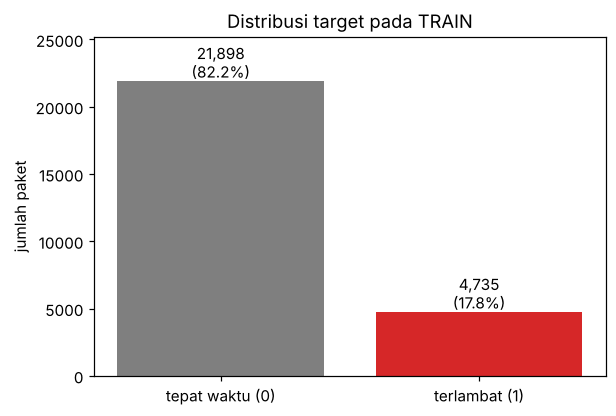

In [7]:
jumlah = train['terlambat'].value_counts().sort_index()
persen = (jumlah / len(train) * 100).round(1)
display(pd.DataFrame({'jumlah': jumlah, 'persen (%)': persen}))
plt.figure(figsize=(6, 4))
plt.bar(['tepat waktu (0)', 'terlambat (1)'], jumlah.values, color=['tab:gray', 'tab:red'])
for i, (j, p) in enumerate(zip(jumlah.values, persen.values)):
    plt.text(i, j, f'{j:,}\n({p}%)', ha='center', va='bottom')
plt.title('Distribusi target pada TRAIN'); plt.ylabel('jumlah paket'); plt.ylim(0, jumlah.max() * 1.15); plt.show()

Sekitar 18% paket terlambat. Kelas tidak seimbang, sehingga akurasi menyesatkan; karena itu dipakai PR-AUC.

### 4.2 Proporsi terlambat menurut tiap faktor

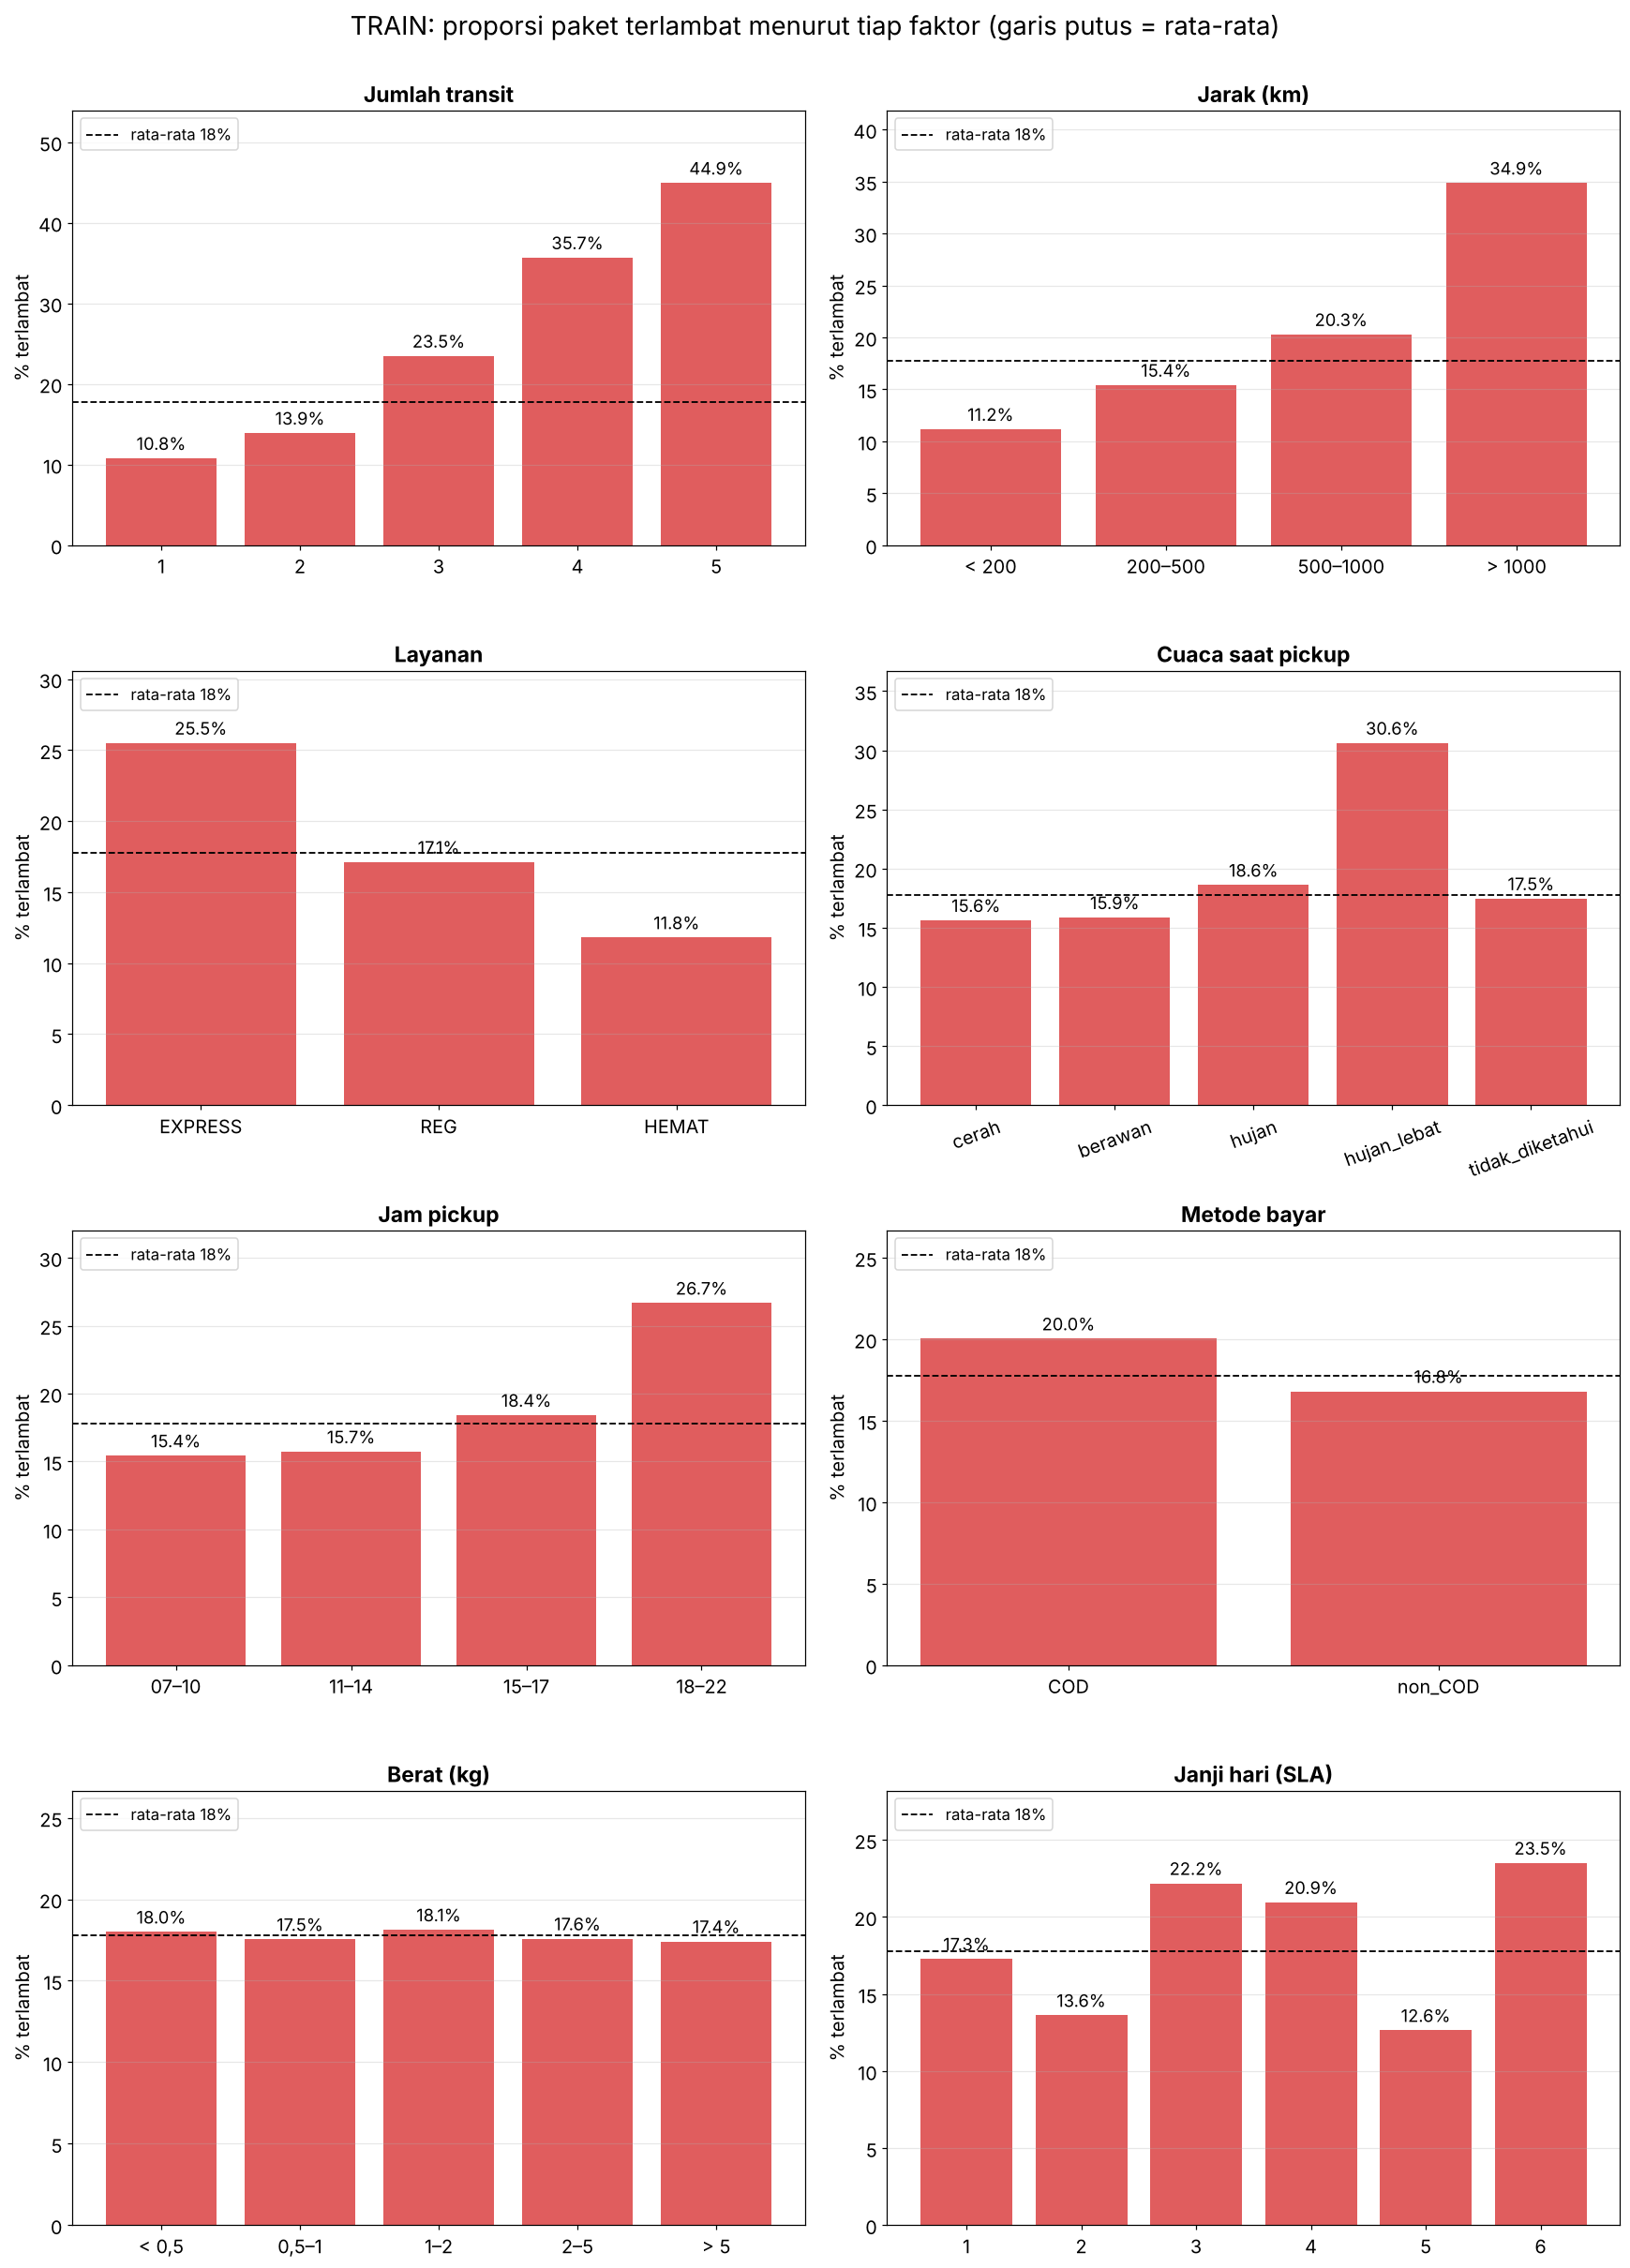

jumlah transit : {1: 10.8, 2: 13.9, 3: 23.5, 4: 35.7, 5: 44.9}
jarak (km)     : {'< 200': 11.2, '200–500': 15.4, '500–1000': 20.3, '> 1000': 34.9}
layanan        : {'EXPRESS': 25.5, 'REG': 17.1, 'HEMAT': 11.8}
cuaca          : {'cerah': 15.6, 'berawan': 15.9, 'hujan': 18.6, 'hujan_lebat': 30.6, 'tidak_diketahui': 17.5}
jam pickup     : {'07–10': 15.4, '11–14': 15.7, '15–17': 18.4, '18–22': 26.7}
metode bayar   : {'COD': 20.0, 'non_COD': 16.8}
berat (kg)     : {'< 0,5': 18.0, '0,5–1': 17.5, '1–2': 18.1, '2–5': 17.6, '> 5': 17.4}
janji hari     : {1: 17.3, 2: 13.6, 3: 22.2, 4: 20.9, 5: 12.6, 6: 23.5}


In [8]:
RATA = train['terlambat'].mean() * 100
plt.rcParams.update({'font.size': 13})

def proporsi(ax, data, kolom, judul, urutan=None):
    p = data.groupby(kolom, observed=True)['terlambat'].mean() * 100
    if urutan is not None:
        p = p.reindex(urutan)
    batang = ax.bar(p.index.astype(str), p.values, color='tab:red', alpha=0.75)
    ax.bar_label(batang, labels=[f'{v:.1f}%' for v in p.values], padding=3, fontsize=12)
    ax.axhline(RATA, color='black', ls='--', lw=1.2, label=f'rata-rata {RATA:.0f}%')
    ax.set_title(judul, fontsize=15, fontweight='bold'); ax.set_ylabel('% terlambat')
    ax.set_ylim(0, max(p.max() * 1.2, RATA * 1.5)); ax.grid(axis='y', alpha=0.3); ax.legend(loc='upper left', fontsize=11)
    return p.round(1)

b = train.copy()
b['jarak'] = pd.cut(b['jarak_km'], [0, 200, 500, 1000, 2500], labels=['< 200', '200–500', '500–1000', '> 1000'])
b['berat'] = pd.cut(b['berat_kg'], [0, 0.5, 1, 2, 5, 50], labels=['< 0,5', '0,5–1', '1–2', '2–5', '> 5'])
b['jam']   = pd.cut(b['jam_pickup'], [6, 10, 14, 17, 22], labels=['07–10', '11–14', '15–17', '18–22'])

fig, axes = plt.subplots(4, 2, figsize=(16, 22))
ringkas = {
    'jumlah transit': proporsi(axes[0, 0], b, 'jumlah_transit', 'Jumlah transit'),
    'jarak (km)':     proporsi(axes[0, 1], b, 'jarak', 'Jarak (km)'),
    'layanan':        proporsi(axes[1, 0], b, 'layanan', 'Layanan', ['EXPRESS', 'REG', 'HEMAT']),
    'cuaca':          proporsi(axes[1, 1], b, 'cuaca_saat_pickup', 'Cuaca saat pickup',
                               ['cerah', 'berawan', 'hujan', 'hujan_lebat', 'tidak_diketahui']),
    'jam pickup':     proporsi(axes[2, 0], b, 'jam', 'Jam pickup'),
    'metode bayar':   proporsi(axes[2, 1], b, 'metode_bayar', 'Metode bayar'),
    'berat (kg)':     proporsi(axes[3, 0], b, 'berat', 'Berat (kg)'),
    'janji hari':     proporsi(axes[3, 1], b, 'janji_hari', 'Janji hari (SLA)'),
}
axes[1, 1].tick_params(axis='x', rotation=20)
plt.suptitle('TRAIN: proporsi paket terlambat menurut tiap faktor (garis putus = rata-rata)', fontsize=18, y=1.0)
plt.tight_layout(); plt.show()
plt.rcParams.update({'font.size': 10})
for nama, p in ringkas.items():
    print(f'{nama:15s}:', p.to_dict())

**Temuan.** Keterlambatan naik tajam dengan jumlah transit dan jarak, lebih tinggi saat hujan lebat dan pickup malam, sedikit lebih tinggi untuk COD. **Berat tidak berpengaruh** (semua kelompok ±18%). EXPRESS paling sering terlambat, dan `janji_hari` sendirian tidak berpola; keduanya dijelaskan di 4.4.

### 4.3 Musim sibuk dan volume hub

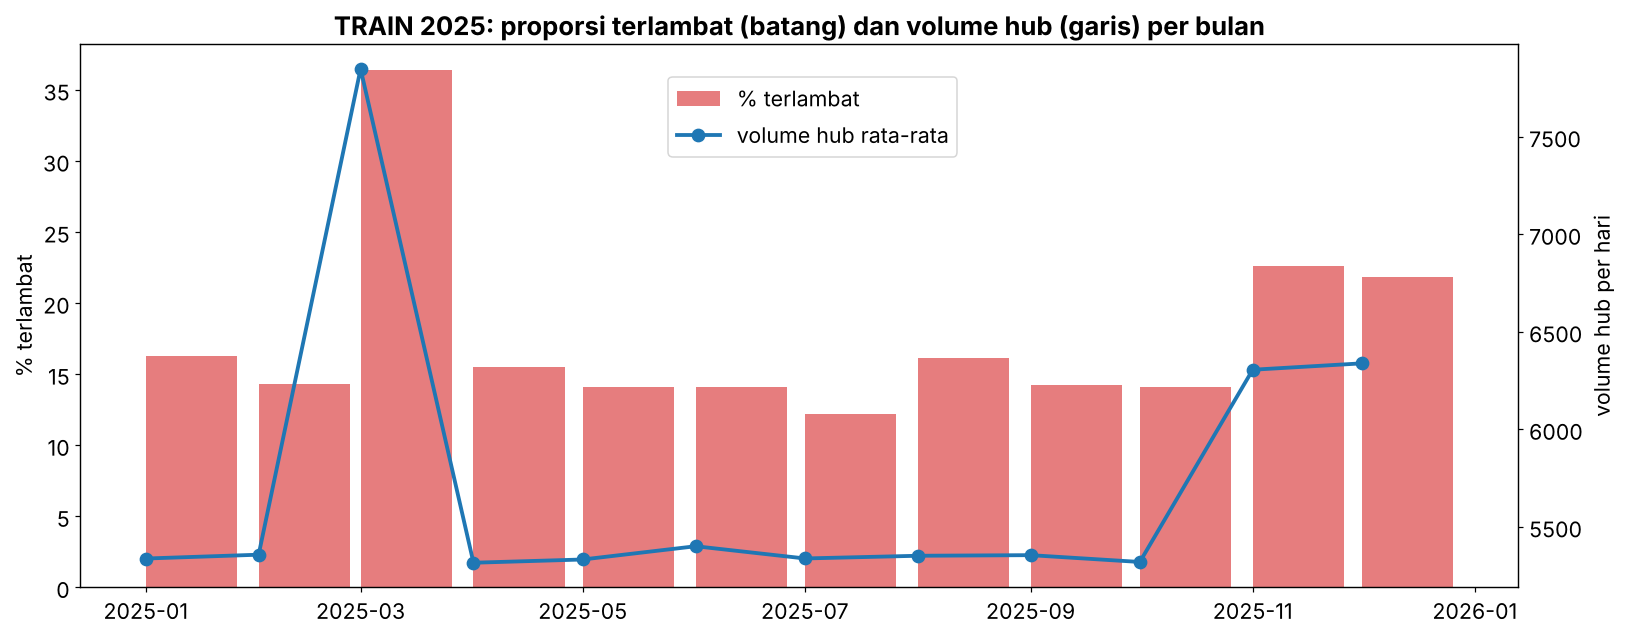

,% terlambat,jumlah paket
volume_hub_hari,,
< 5.000,13.7,8091
5.000–6.000,14.3,12712
6.000–7.000,16.0,3566
7.000–9.000,25.8,639
> 9.000,66.3,1625


In [9]:
plt.rcParams.update({'font.size': 14})
harian = train.groupby('tanggal_pickup').agg(volume=('volume_hub_hari', 'median'), terlambat=('terlambat', 'mean'))
bulanan = harian.resample('MS').mean()

fig, ax1 = plt.subplots(figsize=(15, 6))
ax1.bar(bulanan.index, bulanan['terlambat'] * 100, width=25, align='edge', color='tab:red', alpha=0.6, label='% terlambat')
ax1.set_ylabel('% terlambat')
ax2 = ax1.twinx()
ax2.plot(bulanan.index, bulanan['volume'], color='tab:blue', marker='o', lw=2.5, ms=8, label='volume hub rata-rata')
ax2.set_ylabel('volume hub per hari')
ax1.set_title('TRAIN 2025: proporsi terlambat (batang) dan volume hub (garis) per bulan', fontweight='bold')
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.88)); plt.tight_layout(); plt.show()

kel = pd.cut(train['volume_hub_hari'], [0, 5000, 6000, 7000, 9000, 25000],
             labels=['< 5.000', '5.000–6.000', '6.000–7.000', '7.000–9.000', '> 9.000'])
tabel_vol = train.groupby(kel, observed=True)['terlambat'].agg(['mean', 'size'])
tabel_vol.columns = ['% terlambat', 'jumlah paket']
tabel_vol['% terlambat'] = (tabel_vol['% terlambat'] * 100).round(1)
display(tabel_vol)
plt.rcParams.update({'font.size': 10})

**Temuan.** Keterlambatan melonjak pada Maret (±36%) dan November–Desember (±22%), selalu bersamaan dengan lonjakan volume hub. Pada hari dengan volume di atas 9.000 paket, sekitar dua per tiga paket terlambat. Penyebab yang paling masuk akal adalah hub yang kebanjiran paket, bukan bulannya.

**Masalah kebocoran.** `volume_hub_hari` adalah jumlah paket yang masuk **pada hari itu**. Saat paket dijemput (misalnya pukul 10), total hari itu belum diketahui. Jadi kolom ini berisiko berisi informasi masa depan. Alternatif yang pasti tersedia saat pickup adalah **volume hub kemarin**.

**Catatan kualitas data volume.** `volume_hub_hari` ternyata **tidak sama** untuk paket-paket pada tanggal yang sama. Di TRAIN, semua 365 hari punya lebih dari satu nilai (median 72 nilai berbeda per hari, padahal rata-rata ±73 paket per hari), dan selisih nilai terbesar–terkecil dalam satu hari sekitar 55% dari mediannya. Karena itu, di atas dan pada fitur `volume_hub_kemarin` dipakai **median per hari** sebagai perkiraan volume hari tersebut. Penyebab variasi ini tidak diketahui (data diekspor apa adanya).

Korelasi volume hari ini vs kemarin (TRAIN): 0.744


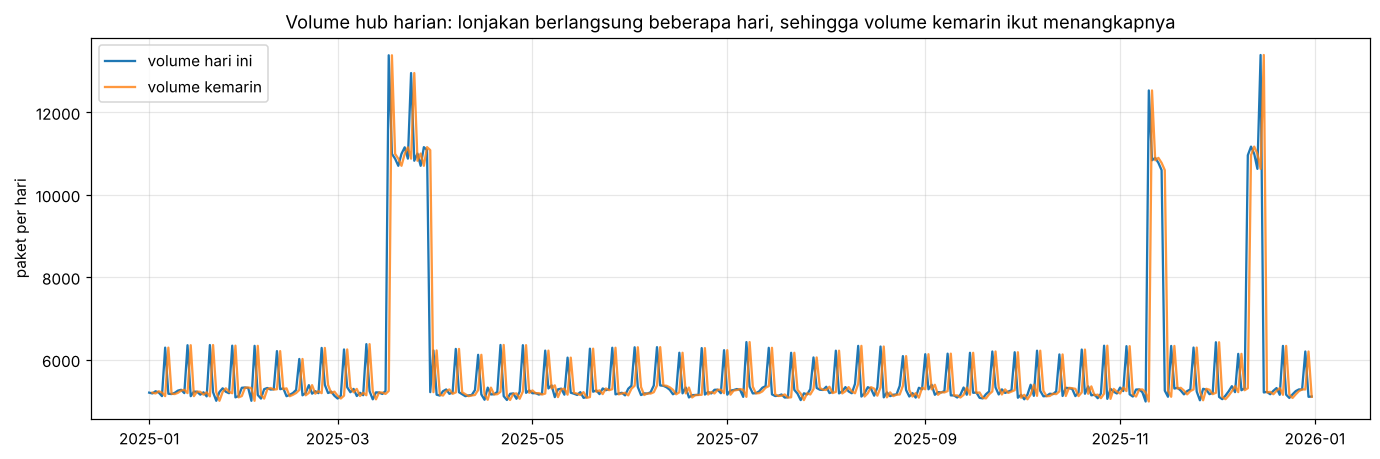

In [10]:
volume_harian = df.groupby('tanggal_pickup')['volume_hub_hari'].median()   # fitur saja (bukan target), dari semua hari
volume_kemarin = volume_harian.shift(1)                                      # nilai hari sebelumnya

cek = harian.join(volume_kemarin.rename('volume_kemarin'))
print('Korelasi volume hari ini vs kemarin (TRAIN):', round(cek['volume'].corr(cek['volume_kemarin']), 3))
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(cek.index, cek['volume'], label='volume hari ini', lw=1.5)
ax.plot(cek.index, cek['volume_kemarin'], label='volume kemarin', lw=1.5, alpha=0.8)
ax.set_title('Volume hub harian: lonjakan berlangsung beberapa hari, sehingga volume kemarin ikut menangkapnya')
ax.set_ylabel('paket per hari'); ax.legend(); ax.grid(alpha=0.3); plt.show()

### 4.4 Layanan × transit dan kelonggaran janji

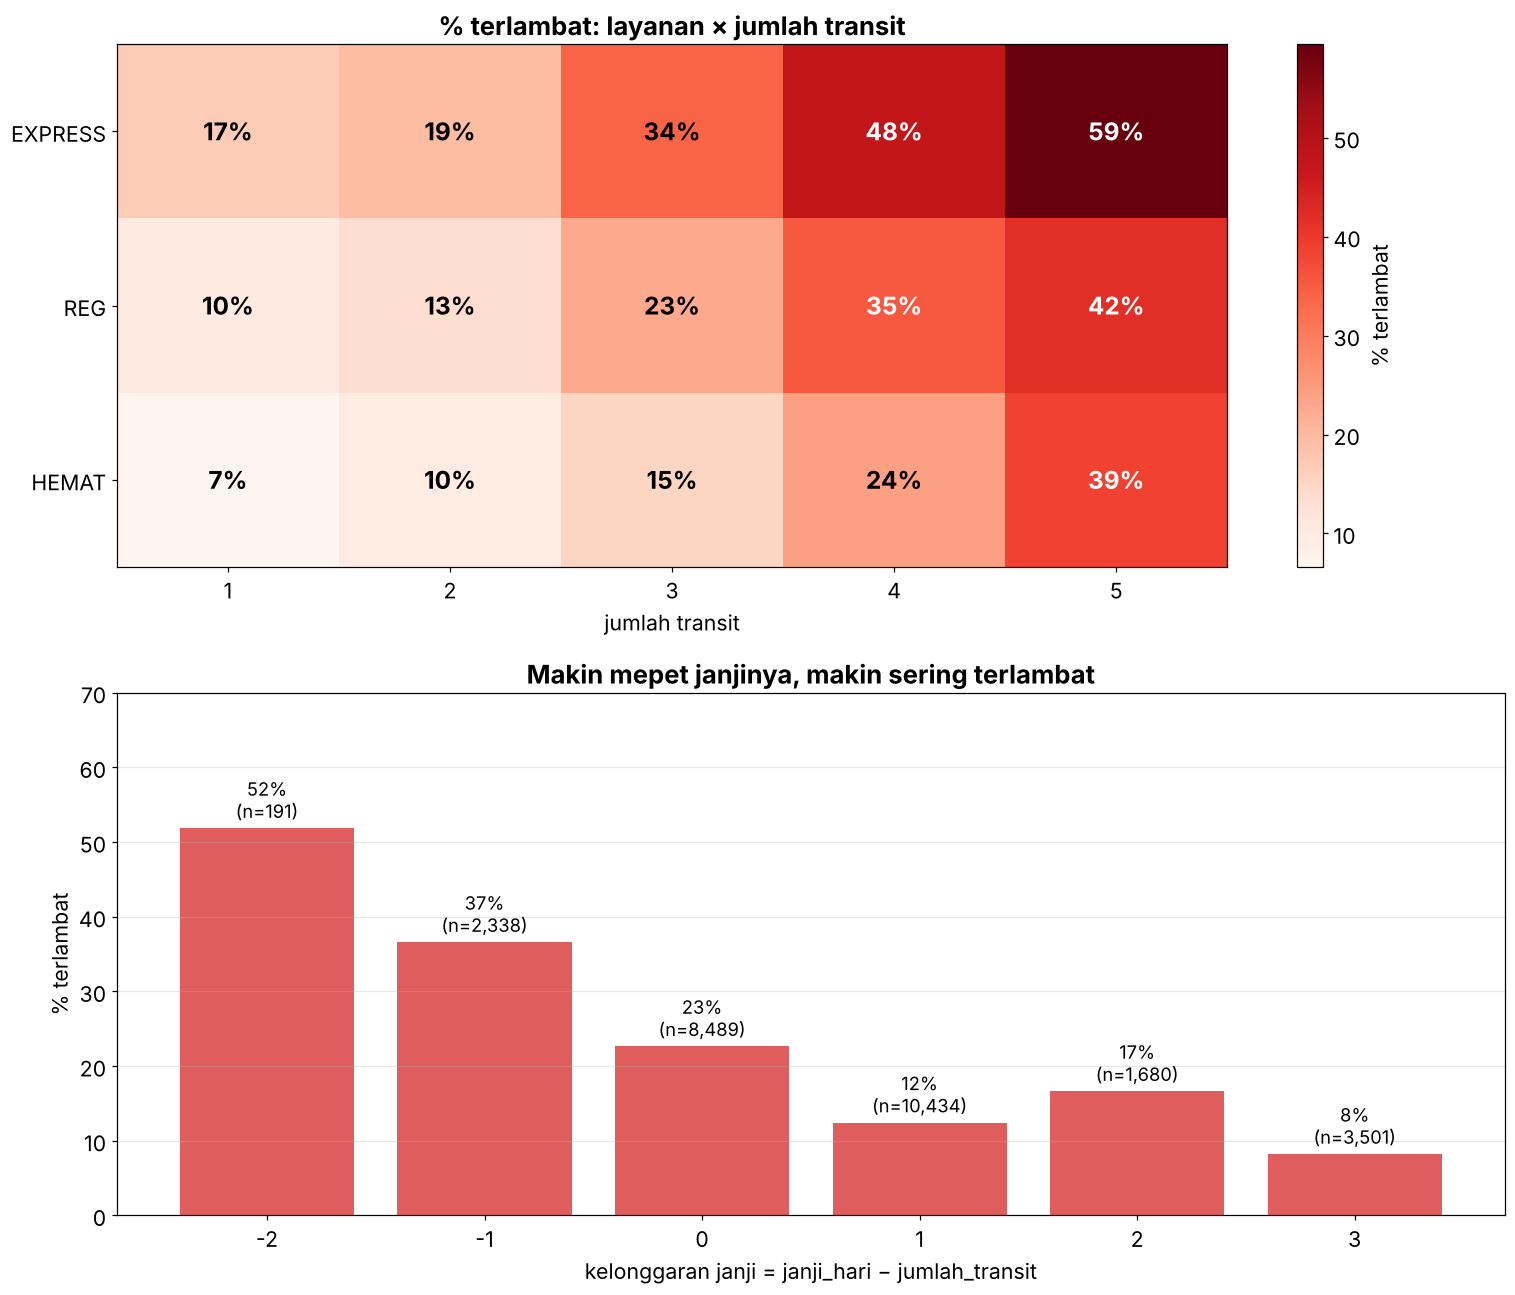

Rata-rata janji per layanan (hari): {'EXPRESS': 1.8, 'HEMAT': 4.7, 'REG': 2.7}


In [11]:
plt.rcParams.update({'font.size': 14})
peta = train.pivot_table(index='layanan', columns='jumlah_transit', values='terlambat', aggfunc='mean').reindex(['EXPRESS', 'REG', 'HEMAT']) * 100
fig, ax = plt.subplots(2, 1, figsize=(14, 12))
im = ax[0].imshow(peta.values, cmap='Reds', aspect='auto')
ax[0].set_xticks(range(peta.shape[1])); ax[0].set_xticklabels(peta.columns)
ax[0].set_yticks(range(peta.shape[0])); ax[0].set_yticklabels(peta.index)
for i in range(peta.shape[0]):
    for j in range(peta.shape[1]):
        v = peta.values[i, j]
        if not np.isnan(v):
            ax[0].text(j, i, f'{v:.0f}%', ha='center', va='center', fontsize=16, fontweight='bold', color='white' if v > 35 else 'black')
ax[0].set_xlabel('jumlah transit'); ax[0].set_title('% terlambat: layanan × jumlah transit', fontweight='bold')
plt.colorbar(im, ax=ax[0], label='% terlambat')

kelonggaran = train['janji_hari'] - train['jumlah_transit']
p = train.groupby(kelonggaran)['terlambat'].agg(['mean', 'size'])
batang = ax[1].bar(p.index.astype(str), p['mean'] * 100, color='tab:red', alpha=0.75)
ax[1].bar_label(batang, labels=[f'{v:.0f}%\n(n={n:,})' for v, n in zip(p['mean'] * 100, p['size'])], padding=4, fontsize=12)
ax[1].set_xlabel('kelonggaran janji = janji_hari − jumlah_transit'); ax[1].set_ylabel('% terlambat')
ax[1].set_title('Makin mepet janjinya, makin sering terlambat', fontweight='bold'); ax[1].set_ylim(0, 70); ax[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
plt.rcParams.update({'font.size': 10})
print('Rata-rata janji per layanan (hari):', train.groupby('layanan')['janji_hari'].mean().round(1).to_dict())

**Temuan.** EXPRESS paling sering terlambat bukan karena lebih lambat, melainkan karena janjinya paling ketat (rata-rata ±1,8 hari). Ukuran yang lebih bermakna adalah **kelonggaran janji** (`janji_hari − jumlah_transit`): makin kecil, makin sering terlambat.

**Ringkasan EDA → fitur**
| Temuan | Fitur |
|---|---|
| transit, jarak, cuaca, jam, COD | dipakai |
| janji mepet | `kelonggaran_janji` |
| pickup malam | `pickup_malam` |
| volume hub (tanpa bocor) | `volume_kemarin`, `volume_kemarin_tinggi` |
| berat tidak berpengaruh | tetap dimasukkan, dicek lewat model |

## 5. Fitur
`buat_fitur` sama persis dengan `src/features.py` di repositori, sehingga aplikasi mengolah input dengan cara yang sama.

In [12]:
def buat_fitur(data, volume_kemarin=volume_kemarin):
    f = data.copy()
    if 'volume_hub_kemarin' not in f:                                  # di aplikasi, nilai ini diisi petugas
        f['volume_hub_kemarin'] = f['tanggal_pickup'].map(volume_kemarin)
    f['kelonggaran_janji']     = f['janji_hari'] - f['jumlah_transit']
    f['pickup_malam']          = (f['jam_pickup'] >= 18).astype(int)
    f['volume_kemarin_tinggi'] = (f['volume_hub_kemarin'] > 9000).astype(int)
    return f

FITUR_ASLI_ANGKA = ['jam_pickup', 'jarak_km', 'jumlah_transit', 'janji_hari', 'berat_kg']
FITUR_KATEGORI   = ['kota_tujuan', 'layanan', 'metode_bayar', 'cuaca_saat_pickup']
FITUR_BUATAN     = ['volume_hub_kemarin', 'volume_kemarin_tinggi', 'kelonggaran_janji', 'pickup_malam']
TARGET = 'terlambat'

train_f, val_f = buat_fitur(train), buat_fitur(val)
y_train, y_val = train_f[TARGET].values, val_f[TARGET].values
display(train_f[FITUR_ASLI_ANGKA + FITUR_BUATAN].describe().round(2))

,jam_pickup,jarak_km,jumlah_transit,janji_hari,berat_kg,volume_hub_kemarin,volume_kemarin_tinggi,kelonggaran_janji,pickup_malam
count,26633.00,26633.00,26633.00,26633.00,26633.00,26558.00,26633.00,26633.00,26633.00
mean,13.55,535.42,2.09,2.90,2.04,5731.33,0.06,0.81,0.13
std,3.40,518.81,1.14,1.24,2.33,1521.43,0.25,1.13,0.34
min,7.00,92.00,1.00,1.00,0.10,4983.00,0.00,-2.00,0.00
25%,11.00,135.00,1.00,2.00,0.73,5154.00,0.00,0.00,0.00
50%,14.00,356.00,2.00,3.00,1.34,5222.00,0.00,1.00,0.00
75%,16.00,786.00,3.00,4.00,2.46,5327.00,0.00,1.00,0.00
max,22.00,2194.00,5.00,6.00,43.77,13391.00,1.00,3.00,1.00


Pipeline di bawah mengisi nilai kosong dengan median/modus **train** (misalnya `volume_hub_kemarin` pada 1 Januari 2025), menstandarkan angka untuk regresi logistik, dan mengubah kategori menjadi kolom 0/1.

In [13]:
def pipa(model, angka, skala=True):
    langkah_angka = [('isi', SimpleImputer(strategy='median'))] + ([('skala', StandardScaler())] if skala else [])
    olah = ColumnTransformer([
        ('angka', Pipeline(langkah_angka), angka),
        ('kategori', Pipeline([('isi', SimpleImputer(strategy='most_frequent')),
                               ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), FITUR_KATEGORI),
    ])
    return Pipeline([('olah', olah), ('model', model)])

bulan_val = val_f['tanggal_pickup'].dt.month.values
def nilai_ap(proba):
    return {'PR-AUC val': average_precision_score(y_val, proba),
            'PR-AUC Jan+Feb': average_precision_score(y_val[bulan_val < 3], proba[bulan_val < 3])}
PR_AUC_ACAK = y_val.mean()
print('PR-AUC tebakan acak di validation:', round(PR_AUC_ACAK, 3))

PR-AUC tebakan acak di validation: 0.219


## 6. Baseline dan keputusan fitur volume
Baseline wajib: **regresi logistik dengan fitur asli**. Karena `volume_hub_hari` berisiko bocor, baseline memakai fitur asli yang tersedia saat pickup. Tabel di bawah juga menunjukkan dampak tiap pilihan kolom volume.

In [14]:
varian = {
    'Baseline: LR fitur asli (tanpa volume)':          FITUR_ASLI_ANGKA,
    'LR fitur asli + volume HARI INI (berisiko bocor)': FITUR_ASLI_ANGKA + ['volume_hub_hari'],
    'LR fitur asli + volume KEMARIN':                   FITUR_ASLI_ANGKA + ['volume_hub_kemarin'],
}
hasil, proba_val = [], {}
for nama, angka in varian.items():
    m = pipa(LogisticRegression(max_iter=3000), angka).fit(train_f[angka + FITUR_KATEGORI], y_train)
    p = m.predict_proba(val_f[angka + FITUR_KATEGORI])[:, 1]
    proba_val[nama] = p
    hasil.append({'model': nama, **nilai_ap(p)})
    if nama.startswith('Baseline'):
        baseline, FITUR_BASELINE = m, angka + FITUR_KATEGORI
display(pd.DataFrame(hasil).set_index('model').round(3))

,PR-AUC val,PR-AUC Jan+Feb
model,,
Baseline: LR fitur asli (tanpa volume),0.409,0.371
LR fitur asli + volume HARI INI (berisiko bocor),0.646,0.364
LR fitur asli + volume KEMARIN,0.588,0.368


Volume adalah informasi terkuat, terutama di musim sibuk (Maret ada di validation). **Volume kemarin** mengembalikan sebagian besar manfaat itu tanpa memakai informasi yang belum tersedia saat pickup, sehingga dipakai pada model berikutnya. Varian "volume hari ini" hanya ditampilkan sebagai pembanding.

## 7. Membandingkan model (fitur asli + fitur buatan)

,PR-AUC train,PR-AUC val,PR-AUC Jan+Feb
model,,,
Baseline: LR fitur asli (tanpa volume),0.380,0.409,0.371
Regresi logistik + fitur buatan,0.485,0.604,0.371
Random Forest + fitur buatan,0.558,0.589,0.377
Gradient Boosting + fitur buatan,0.553,0.585,0.382


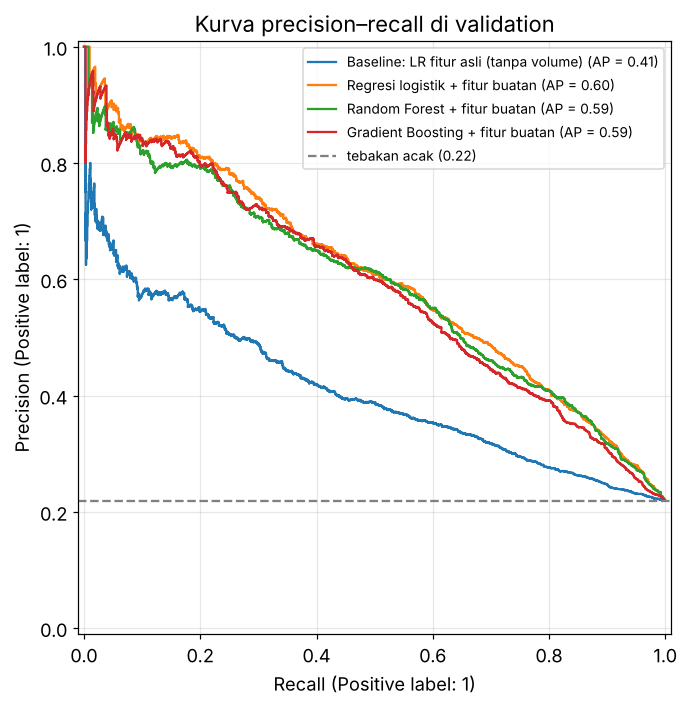

In [15]:
ANGKA_FINAL = FITUR_ASLI_ANGKA + FITUR_BUATAN
KOLOM_FINAL = ANGKA_FINAL + FITUR_KATEGORI
kandidat = {
    'Regresi logistik + fitur buatan': pipa(LogisticRegression(max_iter=3000), ANGKA_FINAL),
    'Random Forest + fitur buatan':    pipa(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1), ANGKA_FINAL, skala=False),
    'Gradient Boosting + fitur buatan': pipa(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42), ANGKA_FINAL, skala=False),
}
baris = [{'model': 'Baseline: LR fitur asli (tanpa volume)', 'PR-AUC train': average_precision_score(y_train, baseline.predict_proba(train_f[FITUR_BASELINE])[:, 1]),
          **nilai_ap(proba_val['Baseline: LR fitur asli (tanpa volume)'])}]
for nama, m in kandidat.items():
    m.fit(train_f[KOLOM_FINAL], y_train)
    proba_val[nama] = m.predict_proba(val_f[KOLOM_FINAL])[:, 1]
    baris.append({'model': nama, 'PR-AUC train': average_precision_score(y_train, m.predict_proba(train_f[KOLOM_FINAL])[:, 1]),
                  **nilai_ap(proba_val[nama])})
tabel_model = pd.DataFrame(baris).set_index('model').round(3)
display(tabel_model)

plt.rcParams.update({'font.size': 12})
fig, ax = plt.subplots(figsize=(9, 7))
for nama in tabel_model.index:
    PrecisionRecallDisplay.from_predictions(y_val, proba_val[nama], ax=ax, name=nama)
ax.axhline(PR_AUC_ACAK, color='gray', ls='--', label=f'tebakan acak ({PR_AUC_ACAK:.2f})')
ax.set_title('Kurva precision–recall di validation'); ax.legend(fontsize=9); ax.grid(alpha=0.3); plt.show()
plt.rcParams.update({'font.size': 10})

PR-AUC validation lebih tinggi daripada train karena validation memuat musim sibuk Maret 2026 (keterlambatan lebih banyak dan lebih mudah ditebak). Kolom **Jan+Feb** menunjukkan kinerja di bulan biasa, yang lebih mirip kondisi sehari-hari.

**Hati-hati membaca kenaikan PR-AUC.** Di bulan biasa (Jan+Feb), regresi logistik + fitur buatan hanya 0,371–0,373, hampir sama dengan baseline (0,371). Hampir seluruh kenaikan PR-AUC validation (0,409 → ±0,60) datang dari **Maret 2026**, musim sibuk yang tertangkap oleh `volume_hub_kemarin`. Gradient Boosting sedikit lebih baik di Jan+Feb (±0,38–0,39), tetapi lebih rendah pada validation keseluruhan.

Aturan pemilihan tetap **PR-AUC validation keseluruhan** (ditetapkan sebelum melihat test), sehingga model final adalah regresi logistik. Artinya: manfaat model terutama terasa saat hub sedang kebanjiran paket; di hari biasa, model ini belum jauh lebih baik dari baseline.

## 8. Tuning kecil dan threshold berbasis biaya

In [16]:
hasil_tuning = []
for C in [0.1, 1, 10]:
    m = pipa(LogisticRegression(C=C, max_iter=3000), ANGKA_FINAL).fit(train_f[KOLOM_FINAL], y_train)
    hasil_tuning.append({'model': 'Regresi logistik', 'pengaturan': f'C={C}', 'objek': m,
                         **nilai_ap(m.predict_proba(val_f[KOLOM_FINAL])[:, 1])})
for lr, depth, leaf in itertools.product([0.03, 0.1], [3, None], [20, 100]):
    m = pipa(HistGradientBoostingClassifier(learning_rate=lr, max_depth=depth, min_samples_leaf=leaf, max_iter=200, random_state=42),
             ANGKA_FINAL, skala=False).fit(train_f[KOLOM_FINAL], y_train)
    hasil_tuning.append({'model': 'Gradient Boosting', 'pengaturan': f'lr={lr}, depth={depth}, leaf={leaf}', 'objek': m,
                         **nilai_ap(m.predict_proba(val_f[KOLOM_FINAL])[:, 1])})
tabel_tuning = pd.DataFrame(hasil_tuning).sort_values('PR-AUC val', ascending=False).reset_index(drop=True)
display(tabel_tuning.drop(columns='objek').round(3))

terbaik_tuning = tabel_tuning.iloc[0]
model_final = terbaik_tuning['objek']
NAMA_MODEL = f"{terbaik_tuning['model']} ({terbaik_tuning['pengaturan']})"
proba_final = model_final.predict_proba(val_f[KOLOM_FINAL])[:, 1]
print('Model final:', NAMA_MODEL, '| PR-AUC val', round(average_precision_score(y_val, proba_final), 3))

,model,pengaturan,PR-AUC val,PR-AUC Jan+Feb
0,Regresi logistik,C=0.1,0.605,0.373
1,Regresi logistik,C=10,0.604,0.371
2,Regresi logistik,C=1,0.604,0.371
3,Gradient Boosting,"lr=0.03, depth=3, leaf=100",0.592,0.387
4,Gradient Boosting,"lr=0.03, depth=3, leaf=20",0.590,0.386
5,Gradient Boosting,"lr=0.03, depth=None, leaf=100",0.585,0.382
6,Gradient Boosting,"lr=0.1, depth=3, leaf=20",0.582,0.381
7,Gradient Boosting,"lr=0.1, depth=3, leaf=100",0.580,0.381
8,Gradient Boosting,"lr=0.1, depth=None, leaf=100",0.579,0.376
9,Gradient Boosting,"lr=0.1, depth=None, leaf=20",0.577,0.386


Model final: Regresi logistik (C=0.1) | PR-AUC val 0.605


**Threshold.** Paket terlambat yang tidak dikabari (FN) = Rp50.000; kabar yang keliru (FP) = Rp5.000; kejadian benar dianggap Rp0 (asumsi). Threshold dipilih yang membuat total biaya validation paling kecil. Secara teori, jika probabilitas terkalibrasi, mengabari lebih murah bila *p* > 5.000 / (5.000 + 50.000) ≈ 0,09.

,threshold,dikabari,TP,FP,FN,recall,biaya (Rp),% paket dikabari
strategi,,,,,,,,
Tidak pernah mengabari,—,0,0,0,"1,449",0%,"Rp72,450,000",0%
Kabari semua paket,—,"6,623","1,449","5,174",0,100%,"Rp25,870,000",100%
Baseline (LR fitur asli),0.01,"6,623","1,449","5,174",0,100%,"Rp25,870,000",100%
Model final,0.10,"4,000","1,304","2,696",145,90%,"Rp20,730,000",60%


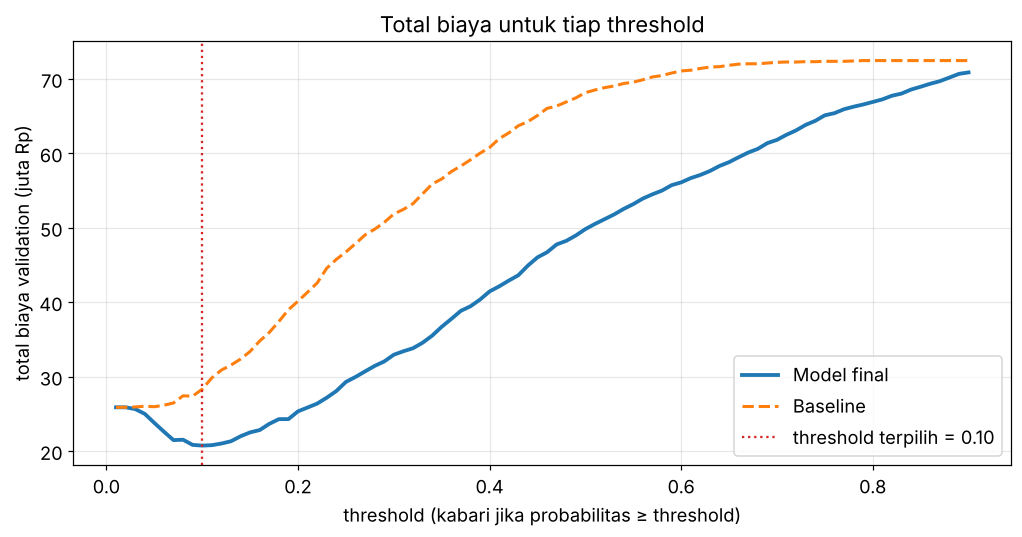

In [17]:
BIAYA_FN, BIAYA_FP = 50_000, 5_000

def hitung_biaya(y, proba, t):
    tn, fp, fn, tp = confusion_matrix(y, (proba >= t).astype(int), labels=[0, 1]).ravel()
    return {'threshold': t, 'dikabari': tp + fp, 'TP': tp, 'FP': fp, 'FN': fn,
            'recall': tp / (tp + fn), 'biaya (Rp)': fn * BIAYA_FN + fp * BIAYA_FP}

daftar_t = np.round(np.arange(0.01, 0.91, 0.01), 2)
kurva_final = pd.DataFrame([hitung_biaya(y_val, proba_final, t) for t in daftar_t])
kurva_base  = pd.DataFrame([hitung_biaya(y_val, proba_val['Baseline: LR fitur asli (tanpa volume)'], t) for t in daftar_t])
THRESHOLD = float(kurva_final.loc[kurva_final['biaya (Rp)'].idxmin(), 'threshold'])
THRESHOLD_BASE = float(kurva_base.loc[kurva_base['biaya (Rp)'].idxmin(), 'threshold'])

pembanding = pd.DataFrame([
    {'strategi': 'Tidak pernah mengabari', **hitung_biaya(y_val, np.zeros(len(y_val)), 0.5)},
    {'strategi': 'Kabari semua paket',     **hitung_biaya(y_val, np.ones(len(y_val)), 0.5)},
    {'strategi': 'Baseline (LR fitur asli)', **hitung_biaya(y_val, proba_val['Baseline: LR fitur asli (tanpa volume)'], THRESHOLD_BASE)},
    {'strategi': 'Model final',            **hitung_biaya(y_val, proba_final, THRESHOLD)},
]).set_index('strategi')
pembanding.loc[['Tidak pernah mengabari', 'Kabari semua paket'], 'threshold'] = np.nan
pembanding['% paket dikabari'] = pembanding['dikabari'] / len(y_val) * 100
display(pembanding.style.format({'threshold': '{:.2f}', 'recall': '{:.0%}', 'biaya (Rp)': 'Rp{:,.0f}',
                                 '% paket dikabari': '{:.0f}%', 'dikabari': '{:,}', 'TP': '{:,}', 'FP': '{:,}', 'FN': '{:,}'}, na_rep='—'))

plt.rcParams.update({'font.size': 12})
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(kurva_final['threshold'], kurva_final['biaya (Rp)'] / 1e6, lw=2.5, label='Model final')
ax.plot(kurva_base['threshold'], kurva_base['biaya (Rp)'] / 1e6, lw=2, ls='--', label='Baseline')
ax.axvline(THRESHOLD, color='tab:red', ls=':', label=f'threshold terpilih = {THRESHOLD:.2f}')
ax.set_xlabel('threshold (kabari jika probabilitas ≥ threshold)'); ax.set_ylabel('total biaya validation (juta Rp)')
ax.set_title('Total biaya untuk tiap threshold'); ax.legend(); ax.grid(alpha=0.3); plt.show()
plt.rcParams.update({'font.size': 10})

**Rekomendasi di aplikasi:** probabilitas < threshold → **aman**; threshold – 0,50 → **kabari pelanggan**; ≥ 0,50 → **prioritaskan**. Batas 0,50 adalah kebijakan tim karena brief tidak memberi biaya untuk memprioritaskan paket.

## 9. Menyimpan model dan metadata

In [18]:
import joblib
from datetime import date

Path('models').mkdir(exist_ok=True)
joblib.dump(model_final, 'models/model.joblib')
metadata = {
    'nama_model': NAMA_MODEL, 'tanggal_dilatih': str(date.today()), 'versi_sklearn': sklearn.__version__,
    'periode_train': '2025-01-01 s.d. 2025-12-31', 'periode_validation': '2026-01-01 s.d. 2026-03-31',
    'fitur_angka': ANGKA_FINAL, 'fitur_kategori': FITUR_KATEGORI,
    'threshold_kabari': THRESHOLD, 'threshold_prioritaskan': 0.50,
    'biaya': {'terlewat_FN': BIAYA_FN, 'salah_kabar_FP': BIAYA_FP},
    'patokan_cleaning': {'median_berat': float(patokan['median_berat']),
                         'jarak_per_kota': {k: float(v) for k, v in patokan['jarak_per_kota'].items()}},
    'metrik_validation': {'pr_auc_model': round(float(average_precision_score(y_val, proba_final)), 3),
                          'pr_auc_baseline': round(float(tabel_model.iloc[0]['PR-AUC val']), 3),
                          'pr_auc_acak': round(float(PR_AUC_ACAK), 3),
                          'biaya_model_rp': int(pembanding.loc['Model final', 'biaya (Rp)'])},
}
Path('models/metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(metadata['metrik_validation'], indent=2), '\nThreshold:', THRESHOLD, '| Model:', NAMA_MODEL)

{
  "pr_auc_model": 0.605,
  "pr_auc_baseline": 0.409,
  "pr_auc_acak": 0.219,
  "biaya_model_rp": 20730000
} 
Threshold: 0.1 | Model: Regresi logistik (C=0.1)


## 10. Evaluasi akhir pada TEST (April–Juni 2026)
⚠️ Jalankan **satu kali**, setelah model dan threshold di atas final. Setelah melihat hasilnya, model dan threshold **tidak diubah lagi**.

Catatan kejujuran: tim pernah mengevaluasi model lain pada periode test ini (16 November dengan model tanpa volume, dan 18 November dengan model yang memakai volume hari ini). Pemilihan model di notebook ini hanya berdasarkan validation, tetapi periode test **bukan lagi data yang sepenuhnya belum pernah dilihat**.

In [ ]:
test = isi_kosong(rapikan(test_mentah), patokan)
test_f = buat_fitur(test)
y_test = test_f[TARGET].values
p_test_final = model_final.predict_proba(test_f[KOLOM_FINAL])[:, 1]
p_test_base  = baseline.predict_proba(test_f[FITUR_BASELINE])[:, 1]

hasil_test = pd.DataFrame([
    {'strategi': 'Tidak pernah mengabari', 'PR-AUC': np.nan, **hitung_biaya(y_test, np.zeros(len(y_test)), 0.5)},
    {'strategi': 'Kabari semua paket',     'PR-AUC': np.nan, **hitung_biaya(y_test, np.ones(len(y_test)), 0.5)},
    {'strategi': 'Baseline (LR fitur asli)', 'PR-AUC': average_precision_score(y_test, p_test_base), **hitung_biaya(y_test, p_test_base, THRESHOLD_BASE)},
    {'strategi': 'Model final',            'PR-AUC': average_precision_score(y_test, p_test_final), **hitung_biaya(y_test, p_test_final, THRESHOLD)},
]).set_index('strategi')
hasil_test.loc[['Tidak pernah mengabari', 'Kabari semua paket'], 'threshold'] = np.nan
hasil_test['% paket dikabari'] = hasil_test['dikabari'] / len(y_test) * 100
print(f'Proporsi terlambat di test: {y_test.mean()*100:.1f}% (= PR-AUC tebakan acak {y_test.mean():.3f})')
display(hasil_test.style.format({'PR-AUC': '{:.3f}', 'threshold': '{:.2f}', 'recall': '{:.0%}', 'biaya (Rp)': 'Rp{:,.0f}',
                                 '% paket dikabari': '{:.0f}%', 'dikabari': '{:,}', 'TP': '{:,}', 'FP': '{:,}', 'FN': '{:,}'}, na_rep='—'))

Proporsi terlambat di test: 13.9% (= PR-AUC tebakan acak 0.139)


,PR-AUC,threshold,dikabari,TP,FP,FN,recall,biaya (Rp),% paket dikabari
strategi,,,,,,,,,
Tidak pernah mengabari,—,—,0,0,0,939,0%,"Rp46,950,000",0%
Kabari semua paket,—,—,"6,744",939,"5,805",0,100%,"Rp29,025,000",100%
Baseline (LR fitur asli),0.360,0.01,"6,744",939,"5,805",0,100%,"Rp29,025,000",100%
Model final,0.362,0.10,"3,567",752,"2,815",187,80%,"Rp23,425,000",53%


**Hasil test (dijalankan satu kali, 18 November 2026).** Proporsi terlambat di test hanya 13,9% dan tidak ada musim sibuk seperti Maret. PR-AUC model final 0,362, hampir sama dengan baseline 0,360, sejalan dengan temuan Jan+Feb di validation: tanpa lonjakan volume, fitur tambahan hampir tidak menambah kemampuan membedakan paket. Dari sisi biaya, model final mengabari 53% paket, menangkap 80% paket yang terlambat, dan biayanya Rp23,4 juta, lebih rendah ±19% dibanding mengabari semua paket (Rp29,0 juta). Baseline dengan threshold 0,01 praktis mengabari semua paket. Model dan threshold tidak diubah setelah melihat hasil ini.

## 11. Keterbatasan
- Model hanya mengetahui kondisi saat pickup; gangguan di perjalanan (truk mogok, penerima tidak di tempat) tidak dapat diprediksi.
- `volume_hub_hari` (hari ini) tidak dipakai karena belum diketahui saat pickup; volume kemarin adalah pengganti yang lebih lemah.
- Belum dipastikan apakah `jumlah_transit` adalah rencana (tersedia saat pickup) atau realisasi; jika realisasi, ada risiko kebocoran.
- Konversi berat > 50 sebagai gram adalah dugaan kuat, bukan kepastian dari klien.
- Biaya Rp0 untuk prediksi yang benar adalah asumsi; data bersifat sintetis.
- Periode test sudah pernah dievaluasi oleh model lain dalam tim (lihat bagian 10).
- Model, pengaturan tuning, dan threshold dipilih pada validation yang sama (termasuk Maret yang sibuk), sehingga angka validation cenderung sedikit optimis.
- Di bulan biasa (Jan+Feb) model final hampir tidak lebih baik dari baseline; keunggulannya terutama di musim sibuk (lihat catatan di bagian 7).
- `volume_hub_hari` bervariasi antarpaket pada tanggal yang sama; volume kemarin dihitung dari median per hari, sebuah penyederhanaan.
- Di aplikasi, `volume_hub_kemarin` harus diisi petugas dari catatan hub; jika kosong, diisi median data train.
